## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

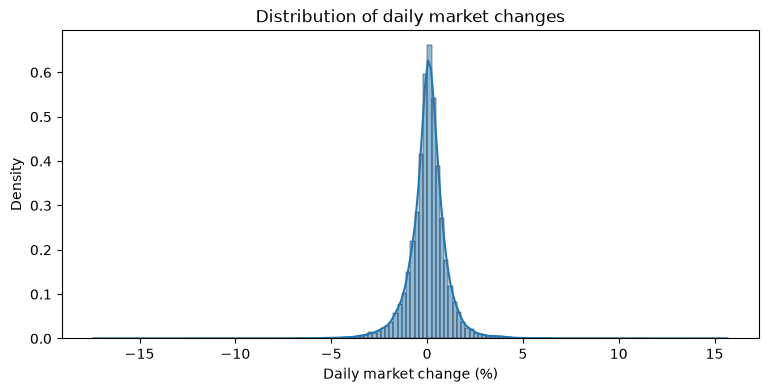

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

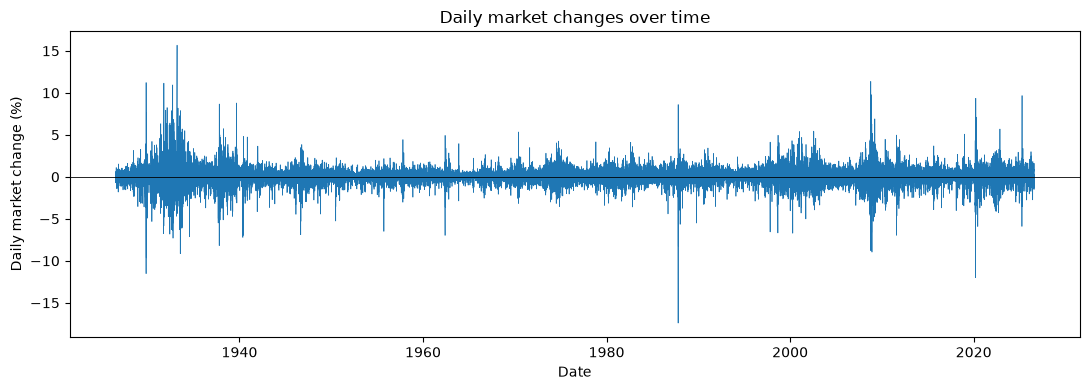

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Part One: Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [4]:
# make a categorical column "direction_t" 

direction_categories = ['Down / flat', 'Up']
np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat')

df['direction_t'] = pd.Categorical(
    np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat'),
    categories=direction_categories,
    ordered=True
)

In [5]:
# make a categorical column "direction_tp1" for the next trading day
df['direction_tp1'] = df['direction_t'].shift(-1)

In [6]:
df[['direction_t', 'direction_tp1']]

,direction_t,direction_tp1
0,Up,Up
1,Up,Up
2,Up,Up
3,Up,Up
4,Up,Down / flat
...,...,...
26291,Up,Up
26292,Up,Down / flat
26293,Down / flat,Up
26294,Up,Up


In [7]:
pd.crosstab(df['direction_t'], df['direction_tp1'], normalize=True, margins = True)

direction_tp1,Down / flat,Up,All
direction_t,,,
Down / flat,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


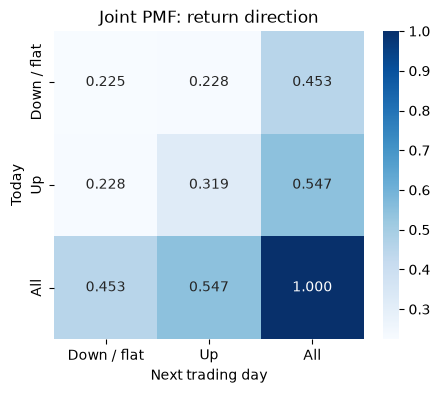

In [8]:
# Plot the joint PMF
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df['direction_t'], df['direction_tp1'], normalize=True, margins = True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

In [9]:
# Plot the conditional PMF

pd.crosstab(df['direction_t'], df['direction_tp1'], normalize='index')

direction_tp1,Down / flat,Up
direction_t,,
Down / flat,0.496221,0.503779
Up,0.416974,0.583026


<div class='alert alert-info'><b>Answer the following:</b>

- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

</div>

There are more ups in general. 

If we condition on today, going from down to up tomorrow, we have .503, which is greater than the transition from up to down. You are more likely to stay up if you are up today. Given up today, we have a .58 chance of being up tomorrow, vs. a .41 chance of being down tomorrow. 

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- Subtract the marginal PMF of tomorrow's state from each row of the conditional PMF, and plot the result as a heatmap. If tomorrow's state were independent of today's, every row of the conditional PMF would equal this marginal. Which transitions are more likely than independence predicts, and which are less likely? Does knowing today's state change the forecast for tomorrow?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [10]:
return_categories = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['return_bin'] = pd.cut(df['market_return_pct'], bins = [-np.inf, -1, -.1, .1, 1, np.inf], labels = return_categories)


In [11]:
df['return_bin'].value_counts()

return_bin
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

In [12]:
#make y_t and y_tp1 columns for the return bins

df['y_t'] = df['return_bin']
df['y_tp1'] = df['return_bin'].shift(-1)

In [13]:
pd.crosstab(df['y_t'], df['y_tp1'], normalize=True, margins=True)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


<div class='alert alert-info'><b>Answer the following:</b>

- How many days fall into each of the five bins?  (use value_counts)
- Which are the most or least common?
  
  </div>

The most amount of days in a bin is for small gain, where there are 9785. The least amount is Large Loss, with 2758, followed closely by 2859. There are 3441 days in the near zero bin, and 7452 in the small loss bin. 

The most common bin is the small gain bin, and the least common bin is the large loss bin, followed closely by large gains. 

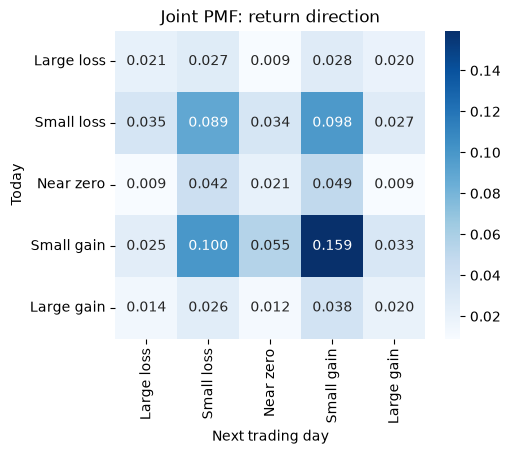

In [14]:
# Plot the joint PMF
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df['y_t'], df['y_tp1'], normalize=True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Which transitions are most likely to occur? 

</div>

The most common transition is from small gain to small gain. Other common occurances are transisitions from small gains to small losses, small losses to small gains and staying with small losses to small losses. 

In [15]:
pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


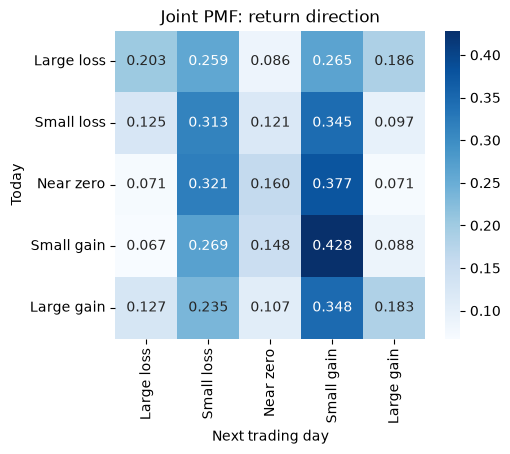

In [16]:
#conditional PMF 
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df['y_t'], df['y_tp1'], normalize='index'),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- For each current state, which two future states are the most likely? 
- Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? 
- Is it relatively easy or difficult to predict the next state?
</div>

Current State: Large Loss
Most Likely Future States: Small loss (.259), Small gain (.265)

Current State: Small Loss
Most Likely Future States: Small Gain (.345), Small loss (.313)

Current State: Near Zero 
Most Likely Future States: Small gain (.377), small loss (.321)

Current State: Small Gain 
Most Likely Future States: Small gain (.428), Small loss (.269)

Current State: Large Gain
Most Likely Future States: Small gain (.348), Small loss (.235)

Each row ranges from .05-.43, which is not very close to a uniform mass function with probability of .2. Each of the rows have similar patterns, with some transitions being more likely that others.

It’s relatively difficult to predict the next state since our highest probability is .43. We can guess there is more likely a small loss or a small gain given what happens today, but these predictions are given with lots of confidence. However, we can make better predictions than if our probability was uniform.

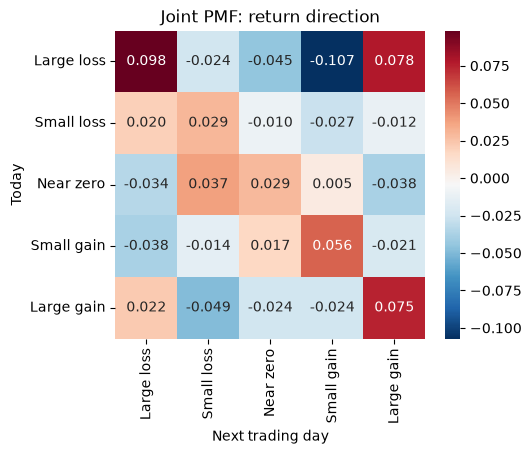

In [17]:
# marginal PMF of tomorrow's state: sum the joint PMF (without margins) down each column
next_state_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True).sum(axis = 0)

next_state_pmf

conditional = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
# subtract it from each row of the conditional PMF and plot as a heatmap
# hint: use .sub(next_state_pmf, axis='columns'), and a diverging colormap such as cmap='RdBu_r' with center=0


fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(conditional.sub(next_state_pmf, axis = 'columns'),
            annot=True, fmt='.3f', cmap='RdBu_r', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Which transitions are more likely than independence predicts, and which are less likely?
- Does knowing today's state change the forecast for tomorrow?
- How is this comparison different from comparing each row to a uniform PMF with probability .2?
</div>

All of the positive values are more likely than independence predicts (red), and the negative values (blue) are less likely then independence predicts. 

Yes, since this are the joint PMFs, today's state does affect tomorrow's forecast. If we didn't know what was happening today, we would not be able to draw any conclusions about tomorrow. 

Independence compares each row to the marginal distribtion of next-day outcomes. The uniform distribution assumes that each of the next day outcomes are equally likely, which is not the case, and not what we are comparing to here. 

In [18]:
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)
# use groupby and describe/mean to get the conditional expectation of the next day's return given today's return bin y_t

df.groupby("y_t")["market_return_pct_tp1"].describe()

/var/folders/rl/vvdz50ss7c34kbs4j9v512jc0000gn/T/ipykernel_34097/307657346.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("y_t")["market_return_pct_tp1"].describe()


,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


<div class='alert alert-info'><b>Answer the following:</b>

- Given the current state, what are the expected percent returns for tomorrow? 
- How do the min and max values for tomorrow vary across states? 
- Which states have the highest standard deviation for tomorrow's percent returns? 
- Describe any patterns in the volatility you notice.
</div>


Given State: Large Loss, Percent Return: -0.038

Given State: Small Loss, Percent Return: -0.0438

Given State: Near Zero, Percent Return: 0.015 

Given State: Small Gain, Percent Return: 0.832

Given State: Large Gain, Percent Return: .163

The large gain and large loss have the biggest spreads of min and max values in both directions, and the near zero has the smallest spread. 

Large loss has the highest standard deviation, with 1.72. Large gain follows behind with 1.38, and then Small Loss with 1.01. Small Gain and Near zero are essentailly tied at 0.83. 

We can see that the volatility is not symmetrical, in regards to the standard deviation of each of these outcomes. The standard deviation of large loss is different from the large gain, and the small loss and small gain standard deviations do not match either. 

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [19]:
#cut into 21 equal-sized bins and make y_t and y_tp1 columns for the return bins
bins = 21
labels = [f"Q{i+1}" for i in range(bins)]

df['y_t'] = pd.qcut(df['market_return_pct'], q=bins, labels=labels)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts(sort=False).rename('Trading days').to_frame().T

y_t,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Q21
Trading days,1255,1253,1286,1280,1230,1226,1371,1206,1198,1331,...,1223,1294,1223,1310,1193,1211,1283,1225,1250,1238


In [20]:
#joint PMF with marginals for the 21 quantile bins + plot as heatmap

quantile_joint = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)

<Axes: xlabel='y_tp1', ylabel='y_t'>

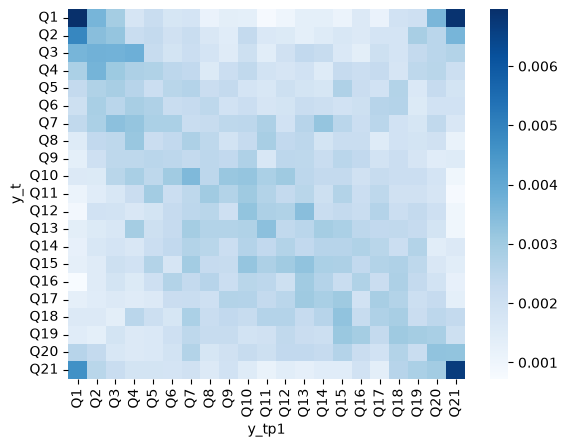

In [21]:
sns.heatmap(quantile_joint, cmap = "Blues")

<Axes: xlabel='y_tp1', ylabel='y_t'>

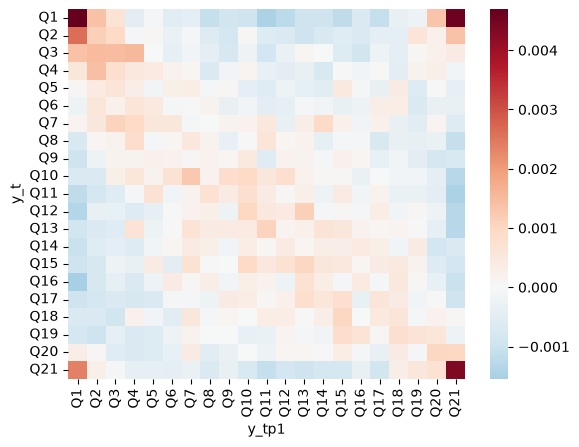

In [22]:
sns.heatmap(quantile_joint - 1/bins**2, cmap = "RdBu_r", center=0)

<Axes: xlabel='y_tp1', ylabel='y_t'>

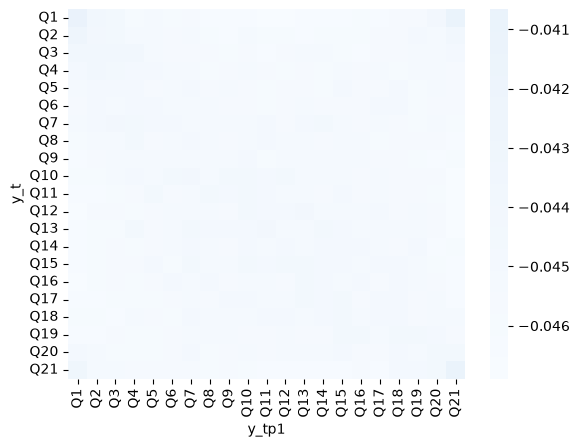

In [23]:
# Subtract 1/21 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.

sns.heatmap(quantile_joint - 1/21, cmap = "Blues", center=0)

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

Not volatile will stay not volatile, and a large loss or gain is more likely to flip.

<Axes: xlabel='y_tp1', ylabel='y_t'>

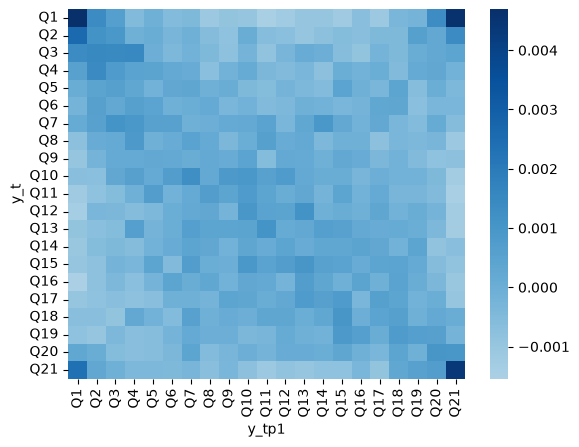

In [36]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.

sns.heatmap(quantile_joint - 1/21**2, cmap = "Blues", center=0)

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

Again, the corners, or the large losses/large gains are more likely given one of these states. 

In [32]:
# compute the next day's min, mean, and max conditional on each bin

# can do this with a .describe 

df.groupby("y_t")["market_return_pct_tp1"].describe()

/var/folders/rl/vvdz50ss7c34kbs4j9v512jc0000gn/T/ipykernel_2422/2502830740.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("y_t")["market_return_pct_tp1"].describe()


,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Q1,1255.0,-0.013713,2.140465,-17.41,-0.9150,-0.02,0.9000,11.22
Q2,1253.0,-0.076712,1.285882,-7.36,-0.7400,-0.02,0.6000,6.36
Q3,1286.0,-0.097084,1.227976,-8.79,-0.7100,-0.03,0.4700,11.36
Q4,1280.0,-0.058594,1.049607,-8.28,-0.5800,0.00,0.4925,6.16
Q5,1230.0,-0.024211,0.989470,-6.89,-0.4675,0.02,0.4675,4.56
Q6,1226.0,-0.022692,1.024761,-11.23,-0.4975,0.02,0.5000,6.37
Q7,1371.0,-0.030241,0.930389,-3.94,-0.4950,0.03,0.4100,7.37
Q8,1206.0,-0.014303,0.835663,-3.40,-0.4200,0.03,0.4100,4.76
Q9,1198.0,0.025860,0.853220,-6.00,-0.3900,0.03,0.4400,5.49


/var/folders/rl/vvdz50ss7c34kbs4j9v512jc0000gn/T/ipykernel_2422/267739611.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("y_t")["market_return_pct_tp1"]


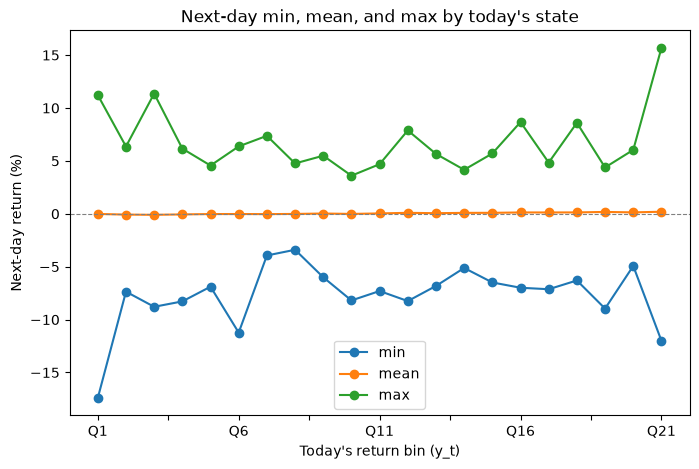

In [ ]:
#plot as lines on a graph against the bins

stats = (
    df.groupby("y_t")["market_return_pct_tp1"]
      .describe()[["min", "mean", "max"]] 
)

fig, ax = plt.subplots(figsize=(8, 5))
stats.plot(ax=ax, marker="o")
ax.axhline(0, color="gray", lw=0.8, ls="--")
ax.set_xlabel("Today's return bin (y_t)")
ax.set_ylabel("Next-day return (%)")
ax.set_title("Next-day min, mean, and max by today's state")
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

When there is a larger minimum, the maximum tends to be larger as well. The mean stays very close to zero. 

/var/folders/rl/vvdz50ss7c34kbs4j9v512jc0000gn/T/ipykernel_2422/4255152278.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("y_t")["market_return_pct_tp1"]


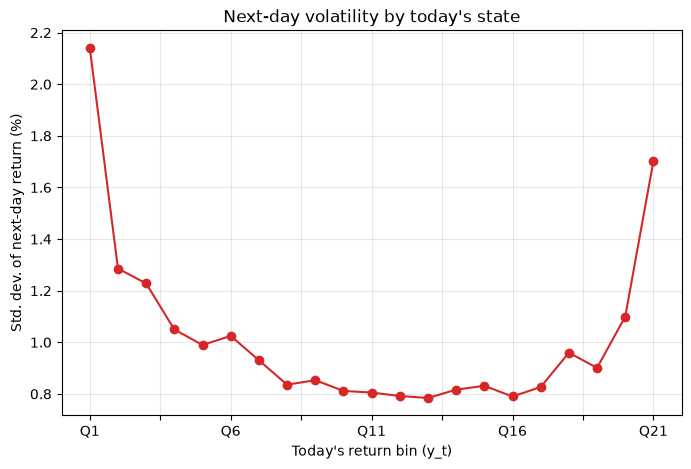

In [35]:
#compute the next day's standard deviation, and plot it as a line graph against the bins. 

std = (
    df.groupby("y_t")["market_return_pct_tp1"]
      .std()
)

fig, ax = plt.subplots(figsize=(8, 5))
std.plot(ax=ax, marker="o", color="tab:red")
ax.set_xlabel("Today's return bin (y_t)")
ax.set_ylabel("Std. dev. of next-day return (%)")
ax.set_title("Next-day volatility by today's state")
ax.grid(alpha=0.3)
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

The tails are extremely volatile, which we can see from the high standard devaitions. 

<div class='alert alert-info'><b>Answer the following:</b>

How easy is it to predict the market?
</div>

The market can be predicted, but we are more likley to have an accurate prediction when the loss or gain is close to zero. When there are large fluctuations, it is harder to predict what will happen to the market. 